# Python cheat sheet

Everything central from the preparation and notebooks 1 and 2, collected in one place. The notebook is meant as a reference: find the operation you need, and copy the cell. All cells can be run again (run the setup cell first), and the results are already shown below the cells.

**Contents:** 1. Setup · 2. Variables, numbers and text · 3. Lists and arrays · 4. Calculating with arrays · 5. Functions and plots · 6. Data with pandas · 7. Error messages

## 1. Setup

The three toolboxes with their fixed short names. This cell must be run first, every time the notebook is opened.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data file from notebook 2, loaded directly from the course GitHub:
DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"
print("Ready.")

Ready.


## 2. Variables, numbers and text

In [2]:
# Variables and the five types
price = 45                # int: whole number
weight = 3.5              # float: decimal number (always a period in code)
shop = "Aalborg C"        # str: text, always in quotation marks
is_open = True            # bool: true or false
prices = [38, 50, 62]     # list: several values in one variable
print(type(price), type(weight), type(shop), type(is_open), type(prices))

<class 'int'> <class 'float'> <class 'str'> <class 'bool'> <class 'list'>


In [3]:
# f-string: merge calculations into text
quantity = 4
print(f"Total: {price * quantity} DKK")

Total: 180 DKK


Remember: a notebook shows the result of the **last line** in a cell by itself. `print` is used when you want to see several results from one cell or mix text and numbers.

## 3. Lists and arrays

A list is a collection. A numpy array is a collection you can **calculate** with. The difference is clearest with multiplication:

In [4]:
# The contrast: list vs array
print([1, 2, 3] * 2)             # list: repeats the content
print(np.array([1, 2, 3]) * 2)   # array: multiplies each number

[1, 2, 3, 1, 2, 3]
[2 4 6]


In [5]:
# Indexing: Python counts from 0
prices = np.array([38, 50, 62, 45, 55, 35])   # Ishuset's menu
print(prices[0])      # first element
print(prices[2])      # third element
print(prices[1:4])    # slice: elements 1, 2 and 3 (stops BEFORE 4)

38
62
[50 62 45]


In [6]:
# 2D array: [row, column]
sales = np.array([[12, 8, 5],
                  [20, 15, 9]])   # two shops, three items
print(sales[0, 2])    # row 0, column 2
print(sales[1, :])    # all of row 1
print(sales[:, 0])    # all of column 0

5
[20 15  9]
[12 20]


## 4. Calculating with arrays

In [7]:
# Elementwise calculation: the operation hits each number
prices = np.array([38, 50, 62])
print(prices * 1.10)          # all prices raised 10 %
print(prices - 5)             # all prices lowered by 5 DKK

[41.8 55.  68.2]
[33 45 57]


In [8]:
# Calculating with rows
print(sales[0, :] + sales[1, :])   # total sales per item across shops
print(sales[1, :] * 2)             # row 1 doubled

[32 23 14]
[40 30 18]


In [9]:
# Dot product with @: multiply pairwise and add up
quantity = np.array([2, 1, 3])       # a family buys ice cream
prices = np.array([38, 50, 62])
print(quantity @ prices)             # 2*38 + 1*50 + 3*62

312


## 5. Functions and plots

The pattern from notebook 1: define a function, make x values with `linspace`, compute y, and draw.

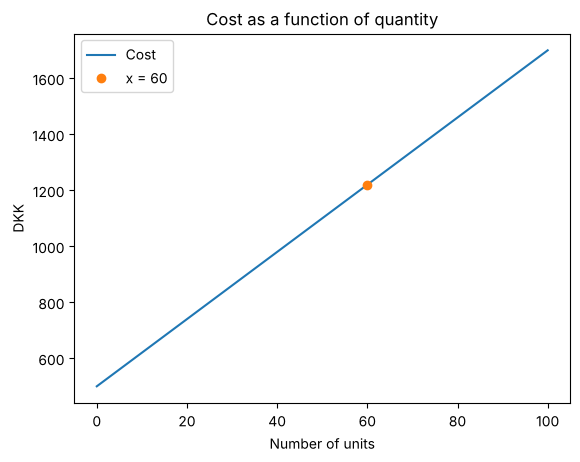

In [10]:
# The whole pattern in one cell: def -> linspace -> plot
def cost(x):
    return 500 + 12 * x          # fixed + variable costs

x = np.linspace(0, 100, 50)      # 50 points from 0 to 100
y = cost(x)

plt.plot(x, y, label="Cost")
plt.plot(60, cost(60), "o", label="x = 60")   # mark one point
plt.xlabel("Number of units")
plt.ylabel("DKK")
plt.title("Cost as a function of quantity")
plt.legend()
plt.show()

## 6. Data with pandas

The order from notebook 2: load, look, compute.

In [11]:
# Load an Excel file into a DataFrame
df = pd.read_excel(DATA_URL)
# From your own uploaded file instead: df = pd.read_excel("ishuset.xlsx")
df.head()    # the first 5 rows

,SaleId,Date,Shop,Item,Quantity,UnitPrice
0,2017,2026-06-01,Aalborg C,Softice,2,45
1,2051,2026-06-01,Skagen,Softice,4,45
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38


In [12]:
# Overview
print(df.shape)    # (rows, columns)
df.describe()      # summary statistics for the numeric columns

(300, 6)


,SaleId,Date,Quantity,UnitPrice
count,300.000000,300,300.000000,300.000000
mean,2150.500000,2026-07-01 20:48:00,2.533333,48.450000
min,2001.000000,2026-06-01 00:00:00,1.000000,35.000000
25%,2075.750000,2026-06-17 00:00:00,1.000000,45.000000
50%,2150.500000,2026-07-01 12:00:00,3.000000,50.000000
75%,2225.250000,2026-07-17 06:00:00,4.000000,55.000000
max,2300.000000,2026-07-31 00:00:00,4.000000,62.000000
std,86.746758,NaN,1.145978,8.020094


In [13]:
# One column and its summary statistics
print(df["Quantity"].mean())
print(df["Quantity"].sum())
print(df["Quantity"].min())
print(df["Quantity"].max())

2.533333333333333
760
1
4


In [14]:
# Count categories
df["Item"].value_counts()

Item
Waffle 2 scoops    101
Softice             63
Waffle 3 scoops     41
Slushice            38
Milkshake           36
Waffle 1 scoop      21
Name: count, dtype: int64

In [15]:
# Computed column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df.head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice,Revenue
0,2017,2026-06-01,Aalborg C,Softice,2,45,90
1,2051,2026-06-01,Skagen,Softice,4,45,180
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,186
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62,124
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38,76


In [16]:
# Filtering: only rows that meet a condition
blokhus = df[df["Shop"] == "Blokhus"]
print(blokhus.shape)
print(f"Revenue in Blokhus: {blokhus['Revenue'].sum()} DKK")

(78, 7)
Revenue in Blokhus: 10217 DKK


In [17]:
# Lookup: find one particular row
df[df["SaleId"] == 2130]

,SaleId,Date,Shop,Item,Quantity,UnitPrice,Revenue
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,186


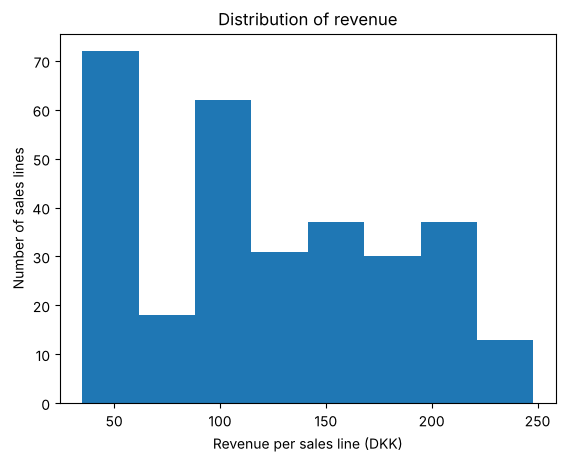

In [18]:
# Histogram of a numeric column
plt.hist(df["Revenue"], bins=8)
plt.xlabel("Revenue per sales line (DKK)")
plt.ylabel("Number of sales lines")
plt.title("Distribution of revenue")
plt.show()

## 7. Error messages

Always read the **bottom line** of the error message first.

| Error | Usually means | Do |
| --- | --- | --- |
| `NameError` | A spelling mistake in a name, or the cell with the definition has not been run | Check the spelling (upper and lower case matter), run the cells from the top |
| `SyntaxError` | Something is missing or in the wrong place: parenthesis, quotation mark, colon | Look at the line the error points to, and the character just before |
| `FileNotFoundError` | The file has not been uploaded, or the name is misspelled | Upload the file again in the Files panel, check the file name |

If nothing works: **Runtime > Restart session**, and then run all cells from the top.